# 03: Trustworthiness

*How well evidenced and traceable is each graph's content?*

| Sub-metric | Definition | Quantification | Scoring |
|---|---|---|---|
| **Edge traceability** | Resolution at which an edge can be traced to its origin database | the graph's own metadata | ordinal tier: 0 type-level, 0.5 per-node, 1.0 per-edge |
| **Source diversity** | Breadth of distinct upstream databases contributing edges | `data/SOURCE_COUNTS.md`, cited per graph | $\log(n) / \log(n_{\max})$ over the panel |
| **Uncertainty quantification** | Fraction of edges carrying a numeric confidence field | the graph's edge attributes | edges with a non-null score / total edges |

The dimension score is the equal-weighted mean of the three.

**Reported, not scored.** Per-edge provenance examples and the Biolink `knowledge_level` breakdown.

**Source counts are documented, not derived.** Four of the six graphs carry no per-edge provenance, so no count can be computed from their edge files. Each figure is verified against the resource's own documentation and imported from `biokgsuite.stats.provenance.DOCUMENTED`, which carries the citation with the number.

**Inputs:** `config/kgs.yaml` · `data/SOURCE_COUNTS.md` · KG edge and node files

**Outputs:** `results/{figures,tables}/03_trustworthiness/` · `results/checkpoints/03_trustworthiness.pkl`

Design notes and justifications: [`README.md`](README.md)

## Set-up

Every graph in `config/kgs.yaml` is evaluated under identical conditions. Nothing here samples or perturbs the graph, so no seed affects the scored metrics; the seed is used only to pick the example edges shown in the provenance diagnostic.

In [1]:
# Pick up edits to src/ without restarting the kernel. Without this, editing a
# module after it has been imported leaves the kernel holding the old version,
# which surfaces as a confusing ImportError for a name that is plainly on disk.
try:
    get_ipython().run_line_magic('load_ext', 'autoreload')
    get_ipython().run_line_magic('autoreload', '2')
except Exception:
    pass                      # not running under IPython (headless runner, plain python)

import gc
import math
import pickle
import random
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# Locate the repo root from any depth, then make the package importable.
# (`pip install -e .` also works and makes this block a no-op.)
_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'config' / 'kgs.yaml').exists())
if str(_root / 'src') not in sys.path:
    sys.path.insert(0, str(_root / 'src'))

import pandas as pd

from biokgsuite.io import Outputs, assert_full_panel, find_config, load_config, load_kg, require
from biokgsuite.stats import provenance
from biokgsuite.stats.provenance import DOCUMENTED, traceability_table
from biokgsuite.viz.dimension03 import fig03_source_diversity
from biokgsuite.viz.style import setup_style

setup_style()

In [2]:
# Parameters are read with require(), never params.get(key, default): a silent
# default lets a run use a value config/params.yaml never mentions.
config = load_config(find_config(_root))
params = config['analysis_params']
BASE   = config['_base_dir']

# Every figure, table and checkpoint goes through `out`, so results land in
# results/{figures,tables}/03_trustworthiness/ and
# results/checkpoints/03_trustworthiness.pkl.
out = Outputs('03_trustworthiness', BASE)

# A run that scores fewer graphs than config/kgs.yaml declares is a
# different experiment, not a smaller one, so it has to be asked for.
ALLOW_PARTIAL_PANEL = False


### Loading

In [3]:
# Free any KG state left by an earlier notebook before loading again, so the
# two sets never coexist in the kernel.
for _v in ('kgs', 'graphs', 'maps', 'preps'):
    globals().pop(_v, None)
gc.collect()

kgs = {}
for name in config['knowledge_graphs']:
    try:
        kg, nodes = load_kg(name, config)
        kgs[name] = {'kg': kg, 'nodes': nodes}
        print(f'{name:12s}: {len(kg):>12,} edges  {len(nodes):>8,} nodes')
    except FileNotFoundError:
        print(f'{name:12s}: [NOT FOUND]')
    except Exception as e:
        print(f'{name:12s}: [ERROR] {e}')

KG_NAMES = list(kgs)
# Refuse to score a panel that is missing graphs.
#
# The broad `except` above keeps one unreadable graph from taking down the run,
# but the cost is that a run finding two of six completes, prints a dimension
# score and writes a checkpoint indistinguishable from a full one. Scores that
# intersect or normalise across the panel then differ from what a full run would
# give, silently. Set ALLOW_PARTIAL_PANEL in the config cell to score a subset
# deliberately; the reduced panel is recorded in the checkpoint either way.
PANEL = assert_full_panel(KG_NAMES, config,
                          allow_partial=ALLOW_PARTIAL_PANEL,
                          notebook='03_trustworthiness')


primekg     : [NOT FOUND]
hetionet    :    2,250,197 edges    47,031 nodes
drkg        : [NOT FOUND]
openbilink  : [NOT FOUND]
biokg       :    2,067,998 edges   105,524 nodes
  matrix: keep_categories=all → retaining every typed node and edge
matrix      : [NOT FOUND]


## 1. Source diversity

Source diversity characterises how many independent upstream resources underpin a graph. Edges corroborated by several sources are less exposed to any one curation pipeline; edges from a single source inherit that source's annotation bias wholesale, a well-documented effect whereby biomedical databases over-annotate well-studied entities (Haynes et al. 2018; Cheung et al. 2013).

**Where the counts come from.** They are not derived from the edge files. Each is taken from the resource's own documentation, verified 2026-09-15, and recorded with its citation in `data/SOURCE_COUNTS.md`. The notebook imports them from `biokgsuite.stats.provenance.DOCUMENTED` so a number and its citation cannot drift apart. The counting rule is stated in that file: a source is a distinct upstream body of evidence contributing edges, as enumerated by the resource itself; literature-derived corpora count, ontologies and identifier-mapping resources supplying only vocabulary do not.

Two counts required a judgement, both recorded in `data/SOURCE_COUNTS.md`:

- **DRKG is 7, not 6.** Its README prose says "six existing databases ... and data collected from recent publications", but its own statistics tables carry seven source columns, and the `Bibliography` column contributes 9,464 entities and 84,756 triplets. Kaniewski et al. 2026 report 6, following the prose.
- **EC-KG (MATRIX) is 95**, the de-duplicated union of the primary sources behind RTX-KG2, ROBOKOP and PrimeKG, not a sum: only 15 of the 95 overlap between RTX-KG2 and ROBOKOP.

> Haynes, W.A., Tomczak, A. & Khatri, P. Gene annotation bias impedes biomedical research. *Sci. Rep.* **8**, 1362 (2018).
>
> Cheung, W.A. et al. Compensating for literature annotation bias when predicting novel drug-disease relationships. *BMC Med. Genomics* **6**(Suppl 2), S3 (2013).

In [4]:
# The scored source counts, with the citation for each. Imported rather than
# retyped: `data/SOURCE_COUNTS.md` and `provenance.DOCUMENTED` are the single
# place these live, so a reviewer can check every number against its source.
source_counts = pd.DataFrame([
    {'KG': kg, 'Sources': d['n'], 'Basis': d['basis'], 'Citation': d['cite']}
    for kg, d in DOCUMENTED.items() if kg in config['knowledge_graphs']
]).set_index('KG')
out.table(source_counts.reset_index(), 'source_counts')
display(source_counts[['Sources', 'Basis']])
print('Citations (also in data/SOURCE_COUNTS.md):')
for kg, r in source_counts.iterrows():
    print(f'  {kg:12s} {r["Sources"]:>3}  {r["Citation"]}')

_missing = [k for k in KG_NAMES if k not in DOCUMENTED]
if _missing:
    raise KeyError(
        f'No verified source count for {_missing}. Add it to '
        f'biokgsuite.stats.provenance.DOCUMENTED with a citation, and record it '
        f'in data/SOURCE_COUNTS.md. A missing count would otherwise score 0 and '
        f'read as a graph with no sources.')

,Sources,Basis
KG,,
hetionet,29,29 publicly available resources
primekg,20,20 high-quality resources
drkg,7,"6 databases + Bibliography, from the README st..."
biokg,13,13 of the 18 databases in Table 1 are ticked i...
openbilink,9,"9 distinct edge-contributing sources (STRING, ..."
matrix,95,95 aggregated knowledge sources across RTX-KG2...


Citations (also in data/SOURCE_COUNTS.md):
  hetionet      29  Himmelstein et al. 2017, eLife 6:e26726; corroborated by Kaniewski et al. 2026, bioRxiv 2026.08.26.747253
  primekg       20  Chandak, Huang & Zitnik 2023, Sci Data 10:67; corroborated by Kaniewski et al. 2026
  drkg           7  DRKG repository README, github.com/gnn4dr/DRKG (tables). NB Kaniewski et al. 2026 report 6, following the README prose
  biokg         13  Walsh, Mohamed & Novacek 2020, CIKM ’20, Table 1
  openbilink     9  OpenBioLink README source table, github.com/OpenBioLink/OpenBioLink; Breit et al. 2020, Bioinformatics 36:4097 (states no total)
  matrix        95  Kaniewski et al. 2026, "Every Cure Knowledge Graph", bioRxiv doi:10.64898/2026.08.26.747253


In [ ]:
# Derived source counts beside the documented ones.
#
# The scored count is documented, not derived, because four of the six graphs
# carry no per-edge provenance to derive one from. That is a defensible choice,
# but it was being asserted without the check: cell 17 claimed
# `provenance.observed_sources` "derives the count where a graph does carry one,
# which is the check on the documented figure", and nothing in the notebook ever
# called it. A stated cross-check that never runs is weaker than no claim.
#
# `Derived` is NaN where the release carries no provenance field. That is a fact
# about the graph, not a zero, and a disagreement between Derived and Documented
# is a finding to report rather than an error to reconcile silently.
inventory = provenance.source_inventory(kgs)
out.table(inventory, 'source_inventory')
display(inventory)

_cmp = inventory.dropna(subset=['Derived'])
if len(_cmp):
    _dis = _cmp[_cmp['Derived'] != _cmp['Documented']]
    print(f'Derivable from the edge files: {len(_cmp)} of {len(inventory)} graphs')
    if len(_dis):
        print('Derived and documented disagree:')
        for _, _r in _dis.iterrows():
            print(f'  {_r["KG"]:12s} derived {_r["Derived"]:>4}  '
                  f'documented {_r["Documented"]:>4}')
        print('  A derived count below the documented one is expected where a '
              'release ships a subset; above it is not, and needs explaining.')
    else:
        print('Derived and documented agree wherever both exist.')
else:
    print('No graph in this panel carries a provenance field, so the documented '
          'counts cannot be cross-checked here.')

In [5]:
# Relation and source distribution per KG.
KG_SCHEMA = {
    'primekg': {
        'mode':  'columns',
        'cols':  ('x_source', 'y_source'),
        'label': 'source',
    },
    'drkg': {
        'mode':  'relation_prefix',
        'label': 'source',
    },
    'hetionet': {
        'mode':   'relation_values',
        'label':  'metaedge',
        'decode': {
            'GpBP': 'Gene-participates-BiologicalProcess',
            'AeG':  'Anatomy-expresses-Gene',
            'Gr>G': 'Gene-regulates-Gene',
            'GiG':  'Gene-interacts-Gene',
            'GrG':  'Gene-regulates-Gene (directed)',
            'CcSE': 'Compound-causes-SideEffect',
            'AdG':  'Anatomy-downregulates-Gene',
            'AuG':  'Anatomy-upregulates-Gene',
            'GpMF': 'Gene-participates-MolecularFunction',
            'GpPW': 'Gene-participates-Pathway',
            'GpCC': 'Gene-participates-CellularComponent',
            'GcG':  'Gene-covaries-Gene',
            'CdG':  'Compound-downregulates-Gene',
            'CuG':  'Compound-upregulates-Gene',
            'DaG':  'Disease-associates-Gene',
            'CtD':  'Compound-treats-Disease',
            'CbG':  'Compound-binds-Gene',
            'DrD':  'Disease-resembles-Disease',
            'DuG':  'Disease-upregulates-Gene',
            'DdG':  'Disease-downregulates-Gene',
            'DpS':  'Disease-presents-Symptom',
            'PCiC': 'PharmacologicClass-includes-Compound',
            'CrC':  'Compound-resembles-Compound',
            'DlA':  'Disease-localizes-Anatomy',
            'CpD':  'Compound-palliates-Disease',
        },
    },
    # OpenBioLink x_source / y_source both carry the asserting database per edge
    # (STRING, STITCH, Bgee, GO, HPO, CDT, DisGeNet, SIDER, UBERON, DO, DrugCentral).
    # Both columns are always identical (set to the edge's source in load_openbilink)
    # so _compute_counts divides by 2 correctly to avoid double-counting.
    'openbilink': {
        'mode':  'columns',
        'cols':  ('x_source', 'y_source'),
        'label': 'source',
    },
    # MATRIX (Every Cure / Biolink) edge_source carries the per-edge
    # asserting database (94 distinct infores CURIEs). x_source / y_source
    # carry per-NODE upstream pipeline (rtxkg2 / robokop / primekg) and are
    # used separately for tier-1 node provenance.
    'matrix': {
        'mode':  'columns',
        'cols':  ('edge_source',),
        'label': 'source',
    },
    'biokg': {
        'mode':   'relation_values',
        'label':  'predicate',
    },
}

def _compute_counts(kg: pd.DataFrame, schema: dict) -> pd.DataFrame:
    '''Compute edge-count distribution for one KG given its schema entry.'''
    mode, label = schema['mode'], schema['label']
    if mode == 'columns':
        cols = [c for c in schema['cols'] if c in kg.columns]
        # One row per EDGE per distinct source naming it. The previous version
        # divided the pooled counts by the number of columns, on the assumption
        # that x_source and y_source always carry the same value. That holds for
        # OpenBioLink, where both are set to the edge's source, and is false for
        # PrimeKG, whose two columns record the source of each ENDPOINT and
        # routinely differ. Counting distinct values per edge is correct for
        # both, and for the single-column case.
        if len(cols) == 1:
            s = kg[cols[0]].dropna()
        else:
            pairs = kg[cols].apply(lambda r: set(r.dropna()), axis=1)
            s = pairs.explode().dropna()
        counts = (s.astype(str).value_counts()
                  .rename_axis(label).rename('n_edges').reset_index())
    elif mode == 'relation_prefix':
        counts = (kg['relation'].str.extract(r'^([^:]+)::')[0].fillna('other')
                  .value_counts().rename_axis(label).rename('n_edges').reset_index())
    elif mode == 'relation_values':
        counts = (kg['relation'].value_counts()
                  .rename_axis(label).rename('n_edges').reset_index())
        if 'decode' in schema:
            counts['description'] = counts[label].map(schema['decode'])
    else:
        raise ValueError(f'unknown source-distribution mode: {mode!r}')
    return counts

kg_counts = {}
for name, data in kgs.items():
    schema = KG_SCHEMA.get(name)
    if schema is None:
        raise KeyError(
            f'{name} has no KG_SCHEMA entry, so its source distribution cannot '
            f'be read. Add one rather than letting the graph drop out silently.')
    counts = _compute_counts(data['kg'], schema)
    kg_counts[name] = counts
    print(f'\n{name} - {schema["label"]} distribution '
          f'({len(counts)} distinct, {counts["n_edges"].sum():,} total edges)')
    display(counts.set_index(schema['label']))


hetionet - metaedge distribution (24 distinct, 2,250,197 total edges)


,n_edges,description
metaedge,,
GpBP,559504,Gene-participates-BiologicalProcess
AeG,526407,Anatomy-expresses-Gene
Gr>G,265672,Gene-regulates-Gene
GiG,147164,Gene-interacts-Gene
CcSE,138944,Compound-causes-SideEffect
AdG,102240,Anatomy-downregulates-Gene
AuG,97848,Anatomy-upregulates-Gene
GpMF,97222,Gene-participates-MolecularFunction
GpPW,84372,Gene-participates-Pathway



biokg - predicate distribution (17 distinct, 2,067,998 total edges)


,n_edges
predicate,
DDI,1334085
PROTEIN_PATHWAY_ASSOCIATION,250118
PPI,113817
PROTEIN_DISEASE_ASSOCIATION,109276
MEMBER_OF_COMPLEX,87452
DRUG_DISEASE_ASSOCIATION,66867
DPI,28033
COMPLEX_IN_PATHWAY,21125
COMPLEX_TOP_LEVEL_PATHWAY,15639


  → Saved: source_diversity.pdf / .png  (300 dpi)


PosixPath('<repo>/results/figures/03_trustworthiness/source_diversity.pdf')

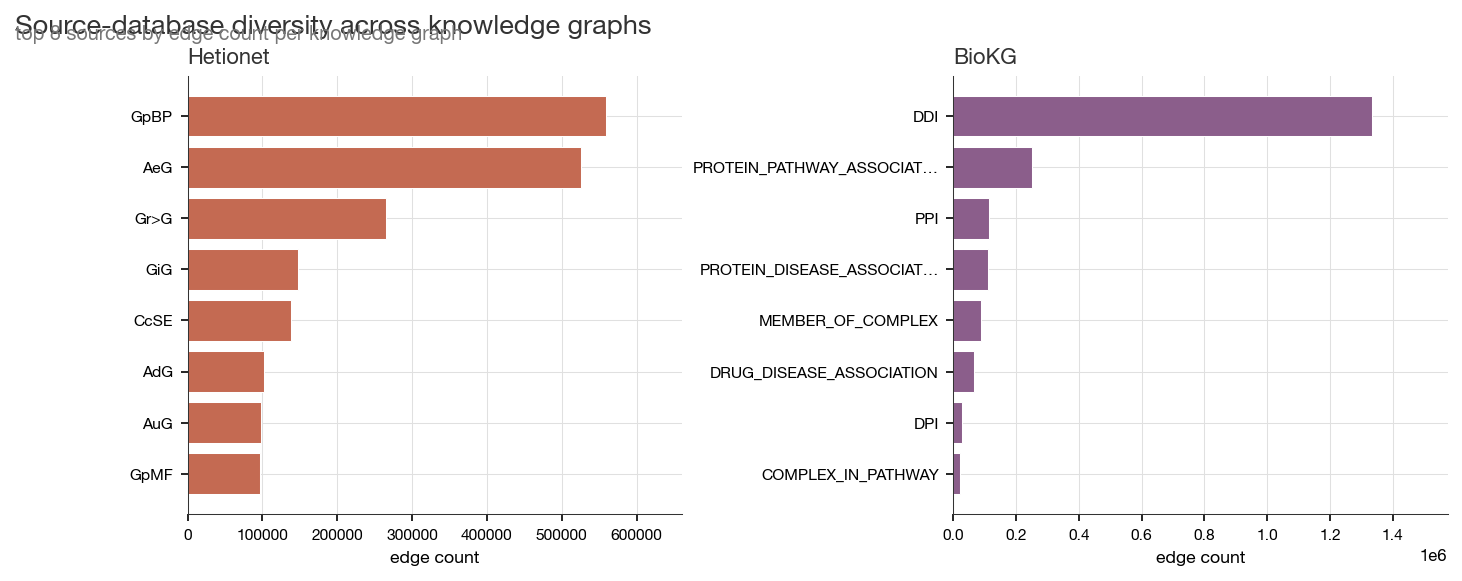

In [6]:
PANEL_CONFIG = {
    'primekg':   {'title': 'PrimeKG',    'label_col': 'source',   'top_n': 8},
    'drkg':      {'title': 'DRKG',       'label_col': 'source',   'top_n': 8},
    'hetionet':  {'title': 'Hetionet',   'label_col': 'metaedge', 'top_n': 8},
    'openbilink':{'title': 'OpenBioLink','label_col': 'source',   'top_n': 8},
    'biokg':     {'title': 'BioKG',      'label_col': 'predicate','top_n': 8},
    'matrix':    {'title': 'Matrix',     'label_col': 'source',   'top_n': 8},
}
out.figure(fig03_source_diversity(kg_counts, PANEL_CONFIG), 'source_diversity')

## 2. Edge traceability

Source diversity says *which* databases contributed. Edge traceability says *how finely an individual edge can be traced back to one*. The distinction that carries the weight is between **node-level** provenance (which database an endpoint's identifier came from) and **edge-level** provenance (which database asserted the relationship). Only the second lets you audit a claim.

**This is computed from the edge files, not assigned.** Each edge is scored by what its provenance supports, and the metric is the mean over edges, i.e. the expected traceability of a randomly chosen edge:

| an edge that | scores |
|---|---|
| names the database that asserted the relationship | 1.0 |
| names only where each endpoint's identifier came from | 0.5 |
| carries no provenance field | 0.0 |

Equivalently, level score x share of edges carrying provenance. Scoring the level alone would ignore how much of a graph actually carries it; scoring the attributed share alone would rank PrimeKG level with DRKG, because PrimeKG populates `x_source`/`y_source` on every edge — fields that name each *endpoint's* origin, not the edge's.

Hetionet shows why the share matters. Twenty of its 24 metaedges carry a per-edge `source` on 100% of edges; four carry none, because they draw on several databases at once (`Anatomy–expresses–Gene` is "according to Bgee **or** TISSUES") and no single source could be named. It scores **0.69**, not 0 and not 1.

> **Format matters, and is recorded.** Hetionet distributes four formats. The TSV export carries only `(source, metaedge, target)`; the JSON and Neo4j formats add node and edge properties, which is why Hetionet's README names them the recommended formats. This pipeline reads the JSON, converted by `tools/convert_hetionet_json.py` and stamped in `data/hetionet/HETIONET_RELEASE.txt`. Read from the TSV, Hetionet scores 0 here — a fact about the file, not the graph.

In [7]:
# Source Granularity Index: the edge traceability tier per KG.
# Source counts are NOT set here. They come from provenance.DOCUMENTED, which
# carries each number with its citation; data/SOURCE_COUNTS.md states the
# counting rule. This dict holds only the provenance MECHANISM per graph.
GRANULARITY_CONFIG = {
    'primekg': {
        'tier':      1,
        'tier_label': '1 - per-node provenance',
        'mechanism': 'Explicit x_source / y_source columns (node-level: records which database each endpoint comes from, not which database asserted the edge)',
        'mode':      'columns',
        'cols':      ('x_source', 'y_source'),
    },
    'drkg': {
        'tier':      2,
        'tier_label': '2 - per-edge provenance',
        'mechanism': 'Source prefix in relation name (SRC::rel::Types) — each edge attributed to the database that asserted the relationship',
        'mode':      'relation_prefix',
    },
    # Hetionet v1.0 carries a per-edge `source` property: describe/definitions.json
    # defines properties.edges as {"source": "The database from which the edge and
    # its properties were gathered"}, which is per-edge provenance by the tier-2
    # definition above. It was previously scored tier 0 on the claim "no per-edge
    # attribution in v1.0", which is false of v1.0 and true only of the TSV
    # export. Hetionet's README: "The JSON and Neo4j formats contain node and edge
    # properties, which are absent in the TSV and matrix formats ... Therefore the
    # recommended formats are JSON and Neo4j." Verified 2026-09-15.
    'hetionet': {
        'tier':      2,
        'tier_label': '2 - per-edge provenance',
        'mechanism': ('Per-edge `source` property naming the database the edge was '
                      'gathered from (hetnet JSON / Neo4j). NOT present in the TSV '
                      'export loaded here, so Edges attributed (%) below reflects '
                      'the distributed format we read, not the graph.'),
        'mode':      'relation_values',
        'provenance_format': 'json/neo4j',   # we currently load: tsv
    },
    # OpenBioLink x_source / y_source record the asserting database for every edge
    # (e.g. STRING, STITCH, Bgee, DisGeNet, SIDER, DrugCentral, GO, HPO, UBERON, DO, CDT).
    # Unlike PrimeKG (tier 1), these fields reflect *which database asserted the relationship*
    # true per-edge provenance , not merely which database the node identifier came from.
    'openbilink': {
        'tier':      2,
        'tier_label': '2 - per-edge provenance',
        'mechanism': 'Explicit x_source / y_source columns encoding the asserting database for each edge (STRING, STITCH, Bgee, DisGeNet, SIDER, DrugCentral, GO, HPO, UBERON, DO, CDT)',
        'mode':      'columns',
        'cols':      ('x_source', 'y_source'),
    },
    # MATRIX exposes BOTH per-node provenance (x_source / y_source = which
    # Translator pipeline ingested each endpoint) AND per-edge provenance
    # (edge_source = the asserting database, e.g. inforesdrugbank). Score
    # against per-edge granularity (the more informative signal); the
    # node-level info is exposed separately for downstream auditing.
    'matrix': {
        'tier':      2,
        'tier_label':'2 - per-edge provenance (also per-node)',
        'mechanism': 'edge_source = primary_knowledge_source (Biolink infores: CURIE) per edge — 94 distinct asserting databases. Plus per-node x_source / y_source (upstream pipeline) and edge-level aggregator_source / edge_upstream — multi-tier provenance.',
        'mode':      'columns',
        'cols':      ('edge_source',),
    },
    'biokg': {
        'tier':      0,
        'tier_label': '0 - type-level',
        'mechanism': None,  # built dynamically from predicate count below
        'mode':      'relation_values',
    },
}

# Edge traceability, computed from the edge files. `PROVENANCE` in
# biokgsuite.stats.provenance declares only the MECHANISM each graph uses (which
# column or relation prefix carries the source, and whether it describes the edge
# or its endpoints); the share of edges actually carrying it is measured here.
traceability = traceability_table(kgs).set_index('KG')
out.table(traceability.reset_index(), 'edge_traceability')
display(traceability)
traceability_scores = traceability['Edge traceability'].to_dict()

_unmeasured = [k for k in KG_NAMES if k not in traceability_scores]
if _unmeasured:
    raise KeyError(
        f'No provenance mechanism declared for {_unmeasured}. Add one to '
        f'biokgsuite.stats.provenance.PROVENANCE. Left undeclared, the graph '
        f'scores 0 for traceability, which reads as a finding about the graph '
        f'rather than a gap in this config.')

,Provenance level,Level score,Edges attributed (%),Edge traceability
KG,,,,
hetionet,edge,1.0,69.0,0.6899
biokg,none,0.0,0.0,0.0000


### Diagnostic edge provenance examples

The following samples illustrate the concrete provenance information available at the edge level in each KG. This helps developers understand *exactly* what metadata is (or is not) attached to individual edges, and where to look when auditing a specific claim.

In [8]:
# What metadata each KG attaches to an individual edge.
random.seed(require(params, 'random_seed'))
N_EDGE_EXAMPLES = 5

for name in KG_NAMES:
    kg = kgs[name]['kg']
    print(f'\n{"=" * 80}')
    print(f'{name.upper()} — edge-level provenance ({len(kg):,} edges, {len(kg.columns)} columns)')
    print(f'{"=" * 80}')

    # Show available columns
    provenance_cols = [c for c in kg.columns
                       if any(kw in c.lower() for kw in
                              ('source', 'evidence', 'pubmed', 'pmid', 'doi',
                               'score', 'confidence', 'weight', 'prob'))]
    print(f'\nProvenance-related columns: {provenance_cols if provenance_cols else "NONE"}')
    print(f'All columns: {list(kg.columns)}\n')

    # Sample edges and display with all columns
    sample_idx = random.sample(range(len(kg)), min(N_EDGE_EXAMPLES, len(kg)))
    sample = kg.iloc[sample_idx]

    # For readability, show only non-index columns with actual content
    show_cols = [c for c in kg.columns if c not in ('x_index', 'y_index')
                 and sample[c].notna().any()]
    display(sample[show_cols])

    # Highlight provenance implications
    cfg = GRANULARITY_CONFIG.get(name, {})  # mechanism text only; level is measured
    tier = cfg.get('tier', -1)
    if tier == 0:
        print('\n→ Tier 0: No per-edge source field. To audit an edge, you must consult')
        print(f'  the original publication to determine which of the {DOCUMENTED[name]["n"]} upstream')
        print('  databases contributed it, using the relation type as the only discriminator.')
    elif tier == 1:
        cols = cfg.get('cols', ())
        print(f'\n→ Tier 1: Node-level provenance via {cols}.')
        print('  You can see which database each endpoint comes from, but NOT which')
        print('  database asserted the relationship between them.')
        # Show cross-source edge example
        if len(cols) == 2:
            cross = kg[kg[cols[0]].notna() & kg[cols[1]].notna() & (kg[cols[0]] != kg[cols[1]])]
            if not cross.empty:
                ex = cross.iloc[0]
                print(f'  Example cross-source edge: {ex[cols[0]]} node ↔ {ex[cols[1]]} node')
    elif tier == 2:
        print('\n→ Tier 2: Per-edge provenance encoded in relation name prefix.')
        print('  Every edge is fully traceable to the database that asserted it.')
        # Show distinct source prefixes
        prefixes = kg['relation'].str.extract(r'^([^:]+)::')[0].dropna().unique()
        print(f'  Source prefixes: {sorted(prefixes)}')


HETIONET — edge-level provenance (2,250,197 edges, 11 columns)

Provenance-related columns: ['edge_source']
All columns: ['relation', 'x_index', 'x_id', 'y_index', 'y_id', 'x_type', 'x_name', 'y_type', 'y_name', 'edge_source', 'unbiased']



,relation,x_id,y_id,x_type,x_name,y_type,y_name,edge_source,unbiased
466956,AeG,Anatomy::UBERON:0000996,Gene::58525,Anatomy,vagina,Gene,WIZ,NaN,1
104902,GpBP,Gene::5045,Biological Process::GO:0042177,Gene,FURIN,Biological Process,negative regulation of protein catabolic process,NCBI gene2go,0
1153556,AeG,Anatomy::UBERON:0002037,Gene::6094,Anatomy,cerebellum,Gene,ROM1,NaN,1
1027150,GiG,Gene::2770,Gene::8698,Gene,GNAI1,Gene,S1PR4,NaN,0
936213,GpBP,Gene::6507,Biological Process::GO:0006820,Gene,SLC1A3,Biological Process,anion transport,NCBI gene2go,0



→ Tier 2: Per-edge provenance encoded in relation name prefix.
  Every edge is fully traceable to the database that asserted it.
  Source prefixes: []

BIOKG — edge-level provenance (2,067,998 edges, 9 columns)

Provenance-related columns: NONE
All columns: ['relation', 'x_index', 'x_id', 'x_type', 'x_name', 'y_index', 'y_id', 'y_type', 'y_name']



,relation,x_id,x_type,x_name,y_id,y_type,y_name
292632,PROTEIN_PATHWAY_ASSOCIATION,P37199,Gene/Protein,NU155,R-RNO-5578749,Pathway,Transcriptional regulation by small RNAs
1544492,DDI,DB00498,Drug,Phenindione,DB14631,Drug,Prednisolone_phosphate
214947,PROTEIN_PATHWAY_ASSOCIATION,Q3T108,Gene/Protein,PSB4,R-BTA-2467813,Pathway,Separation of Sister Chromatids
1419141,DDI,DB11555,Drug,Zolazepam,DB13876,Drug,Brofaromine
1553292,DDI,DB00829,Drug,Diazepam,DB09029,Drug,Secukinumab



→ Tier 0: No per-edge source field. To audit an edge, you must consult
  the original publication to determine which of the 13 upstream
  databases contributed it, using the relation type as the only discriminator.


## 3. Uncertainty quantification

A trustworthy KG should not only record what is known, but also how confidently it is known. We assess whether each KG encodes per-edge confidence scores or uncertainty estimates by scanning for columns whose names contain score-related keywords (`score`, `confidence`, `weight`, `prob`, `evidence`, `support`).

The **uncertainty quantification** sub-metric is the fraction of edges that carry any numeric confidence or evidence-strength annotation:

$$\text{Uncertainty Quantification}_i = \frac{\text{edges with confidence score}_i}{\text{total edges}_i}$$

This metric ranges from 0 (no edges scored) to 1 (every edge has a confidence value). Currently, none of the benchmark KGs provide per-edge confidence scores, yielding 0.0 for all, a finding that motivates future KG design to include quantified evidence strength.

In [9]:
# Availability of a numeric confidence field, per KG.
_SCORE_KEYWORDS = {'score', 'confidence', 'weight', 'prob', 'evidence', 'support'}

def _score_rows(name: str, kg: pd.DataFrame) -> list:
    score_cols = [c for c in kg.columns
                  if any(kw in c.lower() for kw in _SCORE_KEYWORDS)]
    if not score_cols:
        return [{'KG': name, 'Score column': '-- none found --',
                 'Edges with score (%)': 0.0, 'Score range': 'N/A'}]
    rows = []
    for col in score_cols:
        non_null = kg[col].notna().sum()
        pct      = 100 * non_null / len(kg)
        rows.append({
            'KG':                   name,
            'Score column':         col,
            'Edges with score (%)': round(pct, 1),
            'Score range':          f'{kg[col].min():.3g} to {kg[col].max():.3g}'
                                    if pct > 0 else 'N/A',
        })
    return rows

uq_df = pd.DataFrame([
    row
    for name in KG_NAMES
    for row in _score_rows(name, kgs[name]['kg'])
]).set_index('KG')

out.table(uq_df.reset_index(), 'uq_score_fields')
print('Uncertainty / confidence score availability:')
display(uq_df)

# Compute UQ coverage score fraction of edges with any confidence annotation
uq_coverage = {}
for name in KG_NAMES:
    kg = kgs[name]['kg']
    score_cols = [c for c in kg.columns
                  if any(kw in c.lower() for kw in _SCORE_KEYWORDS)]
    if not score_cols:
        uq_coverage[name] = 0.0
    else:
        # Union of edges that have at least one score column populated
        has_any = kg[score_cols].notna().any(axis=1)
        uq_coverage[name] = round(has_any.sum() / len(kg), 4)

print('\nUQ coverage scores (fraction of edges with confidence annotation):')
for kg_name, s in uq_coverage.items():
    print(f'  {kg_name:12s}: {s:.4f}')

Uncertainty / confidence score availability:


,Score column,Edges with score (%),Score range
KG,,,
hetionet,-- none found --,0.0,N/A
biokg,-- none found --,0.0,N/A



UQ coverage scores (fraction of edges with confidence annotation):
  hetionet    : 0.0000
  biokg       : 0.0000


In [10]:
# Biolink knowledge_level: the categorical uncertainty signal, reported only.
# (currently only MATRIX exposes this column; the loop is generic so it
# automatically extends to any future KG that propagates it.)
_KL_ORDER = ['knowledge_assertion', 'logical_entailment', 'statistical_association',
             'observation', 'prediction', 'not_provided']

kl_rows = []
for name in KG_NAMES:
    kg = kgs[name]['kg']
    if 'knowledge_level' not in kg.columns:
        continue
    counts = kg['knowledge_level'].fillna('not_provided').value_counts()
    total  = int(counts.sum())
    for lvl in _KL_ORDER:
        n = int(counts.get(lvl, 0))
        kl_rows.append({
            'KG':                 name,
            'knowledge_level':    lvl,
            'edges':              n,
            'pct':                round(100 * n / total, 2) if total else 0.0,
        })

if kl_rows:
    kl_df = pd.DataFrame(kl_rows)
    print('Biolink knowledge_level distribution:')
    pivot = (kl_df.pivot(index='knowledge_level', columns='KG', values='pct')
             .reindex(_KL_ORDER).fillna(0.0))
    display(pivot)

    # Headline metric fraction of edges with high-trust assertion
    print('\nHigh-trust fraction (knowledge_assertion + logical_entailment):')
    for name in pivot.columns:
        high = pivot.loc[['knowledge_assertion','logical_entailment'], name].sum()
        print(f'  {name:12s}: {high:5.1f}%')
else:
    print('No KG with knowledge_level column found — skipping.')

No KG with knowledge_level column found — skipping.


## Dimension score

$$\text{Trustworthiness} = \tfrac{1}{3}\left(\text{Edge Traceability} + \text{Source Diversity} + \text{Uncertainty Quantification}\right)$$

**Edge traceability** maps the provenance tier to an equally spaced score: tier 0 (type-level only) = 0.00, tier 1 (per-node provenance) = 0.50, tier 2 (per-edge provenance) = 1.00. The distinction that matters is between knowing *which database an identifier came from* and knowing *which database asserted the relationship*; only the latter lets you audit an individual claim.

**Source diversity** is $\log(n_i) / \log(n_{\max})$, with $n_i$ the verified source count for graph $i$ and $n_{\max}$ the largest count in the panel. Every count is imported from `biokgsuite.stats.provenance.DOCUMENTED` and cited in `data/SOURCE_COUNTS.md`; the checkpoint stores the citation alongside each score.

Two properties to report honestly:

- **The ceiling is panel-relative.** Adding a graph with more sources rescales every other graph. These are positions within this benchmark, not absolute properties, and the checkpoint records `source_diversity_max` so any reported value can be traced to the panel it was computed against.
- **The counts are documented, not derived.** No graph's source count is computed from its edge files, because four of the six carry no per-edge provenance at all. `biokgsuite.stats.provenance.observed_sources` derives the count where a graph does carry one, which is the check on the documented figure rather than a replacement for it.

**Uncertainty quantification** is the fraction of edges carrying a numeric confidence or evidence-strength field, computed from the edge files. It is 0 for every graph currently loaded. That is a property of those releases, not of the field: it should be reported as "0 for the graphs evaluated here", since a loader that drops a score column would produce the same number.

In [11]:
# Dimension score. Three sub-metrics, equal-weighted, as in Table 1.
# 1. Edge traceability is computed above, from the edge files.

# 2. Source diversity, log-normalised against the largest count in the panel.
#    The log reflects diminishing marginal information from additional sources
#    (Haynes et al. 2018): the gain from a 5th independent database exceeds the
#    gain from a 30th.
#
#    NOTE the normalisation ceiling is PANEL-RELATIVE, so every graph's score
#    moves when a graph with more sources enters the panel. It is therefore a
#    position within this benchmark, not an absolute property, and must be
#    reported as such. With EC-KG's 95 loaded the ceiling is 95, not 29.
source_counts_n = {kg: DOCUMENTED[kg]['n'] for kg in KG_NAMES}
max_sources = max(source_counts_n.values())
source_diversity_scores = {
    kg: round(math.log(n) / math.log(max_sources), 4) if n > 1 and max_sources > 1 else 0.0
    for kg, n in source_counts_n.items()}

# 3. UQ coverage, computed from the edge files in the cell above.

sub_scores, summary_scores = {}, {}
for kg in KG_NAMES:
    t, d, u = traceability_scores[kg], source_diversity_scores[kg], uq_coverage[kg]
    sub_scores[kg] = {
        'edge_traceability':      t,
        'edges_attributed_pct':   float(traceability.loc[kg, 'Edges attributed (%)']),
        'provenance_level':       traceability.loc[kg, 'Provenance level'],
        'source_diversity':     d,
        'source_diversity_raw': source_counts_n[kg],
        'source_diversity_max': max_sources,
        'source_diversity_cite': DOCUMENTED[kg]['cite'],
        'uq_coverage':          u,
    }
    summary_scores[kg] = round((t + d + u) / 3.0, 4)

scores = pd.DataFrame([
    {'KG': kg, 'trustworthiness': summary_scores[kg],
     'edge_traceability': sub_scores[kg]['edge_traceability'],
     'source_diversity': sub_scores[kg]['source_diversity'],
     'sources (n)': sub_scores[kg]['source_diversity_raw'],
     'uq_coverage': sub_scores[kg]['uq_coverage']}
    for kg in KG_NAMES]).set_index('KG')
out.table(scores.reset_index(), 'dimension_scores')
display(scores)
print(f'Source diversity is normalised against the panel maximum '
      f'({max_sources} sources), so these values are positions within this '
      f'benchmark rather than absolute.')

out.checkpoint({
    'summary_scores':  summary_scores,
    'sub_scores':      sub_scores,
    'traceability':    traceability.reset_index().to_dict('records'),
    'source_counts':   source_counts_n,
    'source_max':      max_sources,
    # Recorded so the paper can state where every count came from without
    # re-deriving it. Full rule and citations: data/SOURCE_COUNTS.md.
    'source_citations': {kg: DOCUMENTED[kg]['cite'] for kg in KG_NAMES},
    'uq_coverage':     uq_coverage,
})
print(out.summary())

,trustworthiness,edge_traceability,source_diversity,sources (n),uq_coverage
KG,,,,,
hetionet,0.5633,0.6899,1.0000,29,0.0
biokg,0.2539,0.0000,0.7617,13,0.0


Source diversity is normalised against the panel maximum (29 sources), so these values are positions within this benchmark rather than absolute.
03_trustworthiness: wrote 7 files
  results/checkpoints/03_trustworthiness.pkl
  results/figures/03_trustworthiness/source_diversity.pdf
  results/figures/03_trustworthiness/source_diversity.png
  results/tables/03_trustworthiness/dimension_scores.csv
  results/tables/03_trustworthiness/edge_traceability.csv
  results/tables/03_trustworthiness/source_counts.csv
  results/tables/03_trustworthiness/uq_score_fields.csv


In [12]:
# Figure-data cache: exactly the inputs results/figures can be rebuilt from
# without reloading the raw KGs (tools/regenerate_figs.py).
_figdata = {'kg_counts': kg_counts, 'panel_config': PANEL_CONFIG}
with open(BASE / 'results' / 'checkpoints' / '03_figdata.pkl', 'wb') as _f:
    pickle.dump(_figdata, _f)
print('figure-data cache -> 03_figdata.pkl | keys:', list(_figdata))

figure-data cache -> 03_figdata.pkl | keys: ['kg_counts', 'panel_config']


In [13]:
# Free KG state before the next notebook, which loads the same graphs again.
# Without this both sets stay resident and the kernel is OOM-killed.
for _v in ('kgs', 'graphs', 'maps', 'preps'):
    globals().pop(_v, None)
print(f'Released KG state; {gc.collect():,} objects collected.')
print('\nTrustworthiness: ' + '  '.join(f'{k} {v:.4f}' for k, v in summary_scores.items()))

Freed KG state from kernel memory.
